# Loan Default Prediction — Exploratory Data Analysis

This notebook walks through the data before any model is trained. It answers four
questions:

1. What does the dataset contain, and how clean is it?
2. Which applicant and loan characteristics are associated with default?
3. Which columns are redundant or risky (leakage)?
4. How do we split the data and preprocess it **without leaking** test information?

**Dataset:** [Credit Risk Dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset)
(CC0 public domain, 32,581 loans). **Target:** `loan_status` — `1` = default.

> Every number below is produced by running the cells, not typed by hand.

## 0. Setup

We import the project's own `src` modules so the notebook and the production code
share exactly the same cleaning and preprocessing logic.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():  # notebook may run from notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src.preprocessing import (
    FEATURE_COLUMNS,
    MAX_PLAUSIBLE_AGE,
    MAX_PLAUSIBLE_EMPLOYMENT_YEARS,
    TARGET,
    build_preprocessor,
    clean_data,
    cleaning_report,
    load_data,
    split_data,
)
from src.eda import FIGURES_DIR, run_eda

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

print("Notebook ready.")

Notebook ready.


## 1. Load the real dataset and look at its structure

`load_data()` checks that the file exists and that all expected columns are present.
It raises a clear error instead of failing later with a confusing `KeyError`.

In [2]:
raw = load_data(PROJECT_ROOT / "data" / "credit_risk_dataset.csv")
print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 32,581 | Columns: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
raw.dtypes.to_frame("dtype")

,dtype
person_age,int64
person_income,int64
person_home_ownership,str
person_emp_length,float64
loan_intent,str
loan_grade,str
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64


### Data-quality snapshot

The table reports the type, missing count, missing percentage and number of unique
values for every column. Exact duplicate rows are counted separately.

In [4]:
quality = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "missing_pct": (raw.isna().mean() * 100).round(2),
        "unique": raw.nunique(),
    }
)
print(f"Exact duplicate rows: {raw.duplicated().sum():,}")
quality

Exact duplicate rows: 165


,dtype,missing,missing_pct,unique
person_age,int64,0,0.00,58
person_income,int64,0,0.00,4295
person_home_ownership,str,0,0.00,4
person_emp_length,float64,895,2.75,36
loan_intent,str,0,0.00,6
loan_grade,str,0,0.00,7
loan_amnt,int64,0,0.00,753
loan_int_rate,float64,3116,9.56,348
loan_status,int64,0,0.00,2
loan_percent_income,float64,0,0.00,77


In [5]:
target_counts = raw[TARGET].value_counts().sort_index()
display(
    pd.DataFrame(
        {
            "count": target_counts,
            "percent": (target_counts / len(raw) * 100).round(2),
        }
    )
)
print(
    f"A model that always predicts 'no default' would score "
    f"{(raw[TARGET] == 0).mean():.2%} accuracy and catch zero defaulters."
)

,count,percent
loan_status,,
0,25473,78.18
1,7108,21.82


A model that always predicts 'no default' would score 78.18% accuracy and catch zero defaulters.


**Interpretation.** About 22% of loans defaulted, so the classes are imbalanced.
This is why the project will report precision, recall, F1 and ROC-AUC alongside
accuracy. Accuracy alone can look good while the model misses every risky loan.

## 2. Cleaning decisions

| Problem | Decision | Why |
|---|---|---|
| 165 exact duplicates | Remove | They are not extra evidence and can leak across train/test |
| Ages 123, 144 | Set to `NaN` | Impossible for this population; the rest of the row stays useful |
| Employment length 123 years | Set to `NaN` | Physically impossible |
| Employment longer than age | Set to `NaN` | Impossible |
| Missing `loan_int_rate` / `person_emp_length` | Impute **inside the pipeline** | Medians must be learned from training data only |
| High income / loan amount | Keep, then `log1p` | Genuine extremes are not errors; log reduces their leverage |

We deliberately **do not** delete rows for invalid values. Deleting them would
throw away valid information in the other eleven columns. Age 84 is unusual but
plausible, so the threshold is 100, not 80.

In [6]:
report = cleaning_report(raw)
pd.Series(report, name="value").to_frame()

,value
rows,32581
duplicate_rows,165
impossible_age,5
impossible_employment_length,2
employment_longer_than_life,2
missing_person_emp_length,895
missing_loan_int_rate,3116


In [7]:
clean = clean_data(raw)
print(f"Raw rows   : {len(raw):,}")
print(f"Clean rows : {len(clean):,}")
print(f"Removed    : {len(raw) - len(clean):,} (exact duplicates)")
print(f"Raw max age: {raw['person_age'].max()} -> clean max age: {clean['person_age'].max()}")
print(f"Target values after cleaning: {sorted(clean[TARGET].unique())}")

Raw rows   : 32,581
Clean rows : 32,416
Removed    : 165 (exact duplicates)
Raw max age: 144 -> clean max age: 94.0
Target values after cleaning: [np.int64(0), np.int64(1)]


`clean_data()` works on a copy: the raw DataFrame is unchanged. It only applies
row-wise, stateless rules. No median, no category frequency and no scaling is
learned here, so running it before the split cannot leak test information.

### Run the reusable EDA report

The same charts are saved to `reports/figures/` and summarised in
`reports/eda_findings.md` for the GitHub README.

In [8]:
summary = run_eda(raw)
print("Figures saved to:", FIGURES_DIR.relative_to(PROJECT_ROOT))
print("Markdown report:", (PROJECT_ROOT / "reports" / "eda_findings.md").relative_to(PROJECT_ROOT))

def show_figure(filename: str, width: int = 900) -> None:
    display(Image(filename=str(FIGURES_DIR / filename), width=width))

Figures saved to: reports/figures
Markdown report: reports/eda_findings.md


## 3. Class imbalance

A 78/22 split means the minority class (default) is the one the bank actually
cares about. "Always predict no default" is the trap baseline.

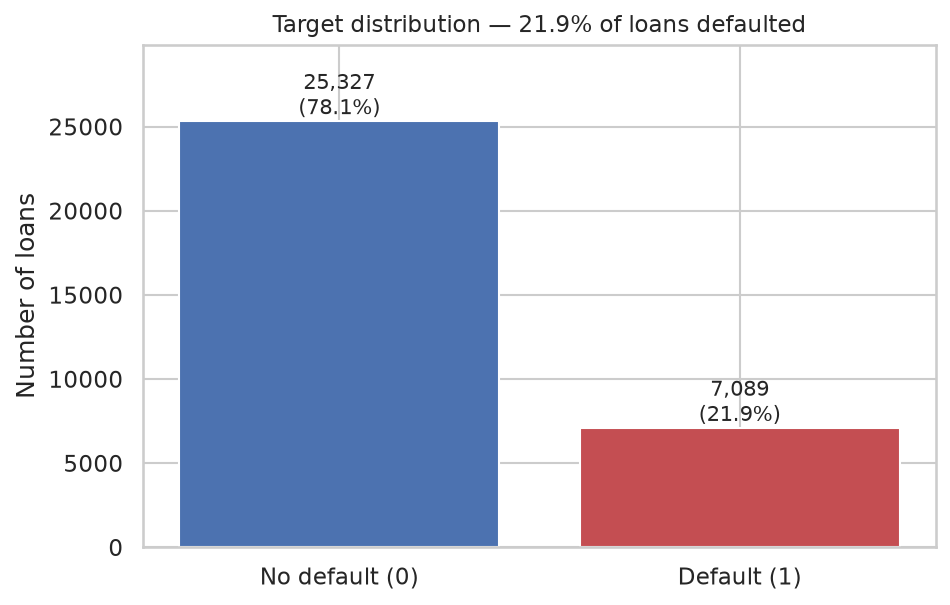

In [9]:
show_figure("01_target_distribution.png", width=620)

## 4. Missing values

Only two columns have missing data. Missingness is not automatically harmless:
if it is related to the target, the model should be told that a value was missing.

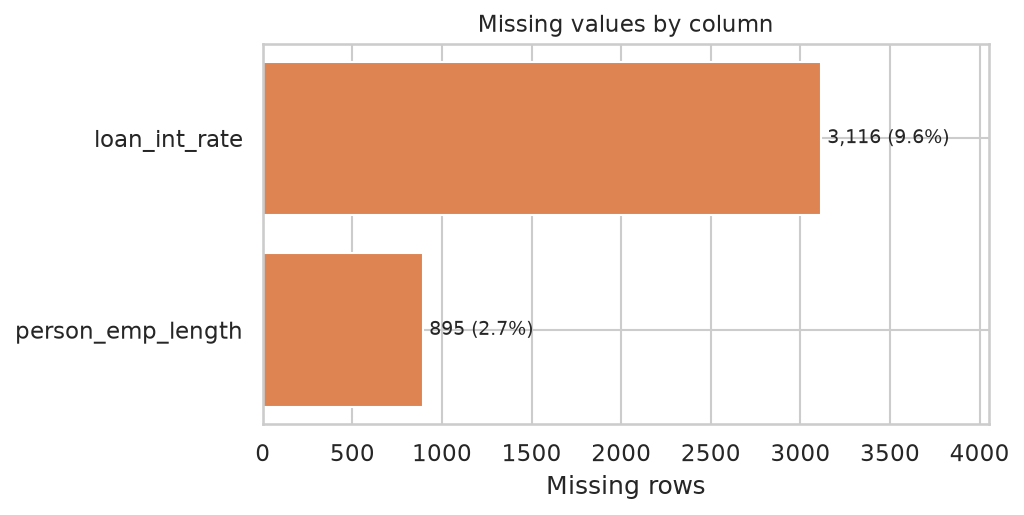

In [10]:
show_figure("02_missing_values.png")

In [11]:
pd.DataFrame(summary["missingness_vs_target"]).T.round(3)

,default_rate_when_present,default_rate_when_missing
person_emp_length,0.216,0.317
loan_int_rate,0.220,0.207


**Interpretation.** Loans with a missing employment length default at **31.7%**
versus **21.6%** when it is present. That is a meaningful difference, so the
pipeline adds a binary missing-value indicator instead of only filling the median.
For `loan_int_rate` the difference is small, but the indicator costs almost
nothing and keeps the option open for the model. Cleaning also turns impossible
ages (123 and 144) into missing values, so `person_age` gets an indicator too — you
will see three `missingindicator` columns in the encoded feature list below.

## 5. Numerical distributions and outliers

Income has skewness around 33 — a few very high earners stretch the x-axis. The
model keeps those genuine observations, but the pipeline applies `log1p` to income
and loan amount so extreme values have less leverage. A preliminary 5-fold CV check
with Logistic Regression showed ROC-AUC improving from 0.865 to 0.873 with this
transform; Stage 4 will re-check it across all three models.

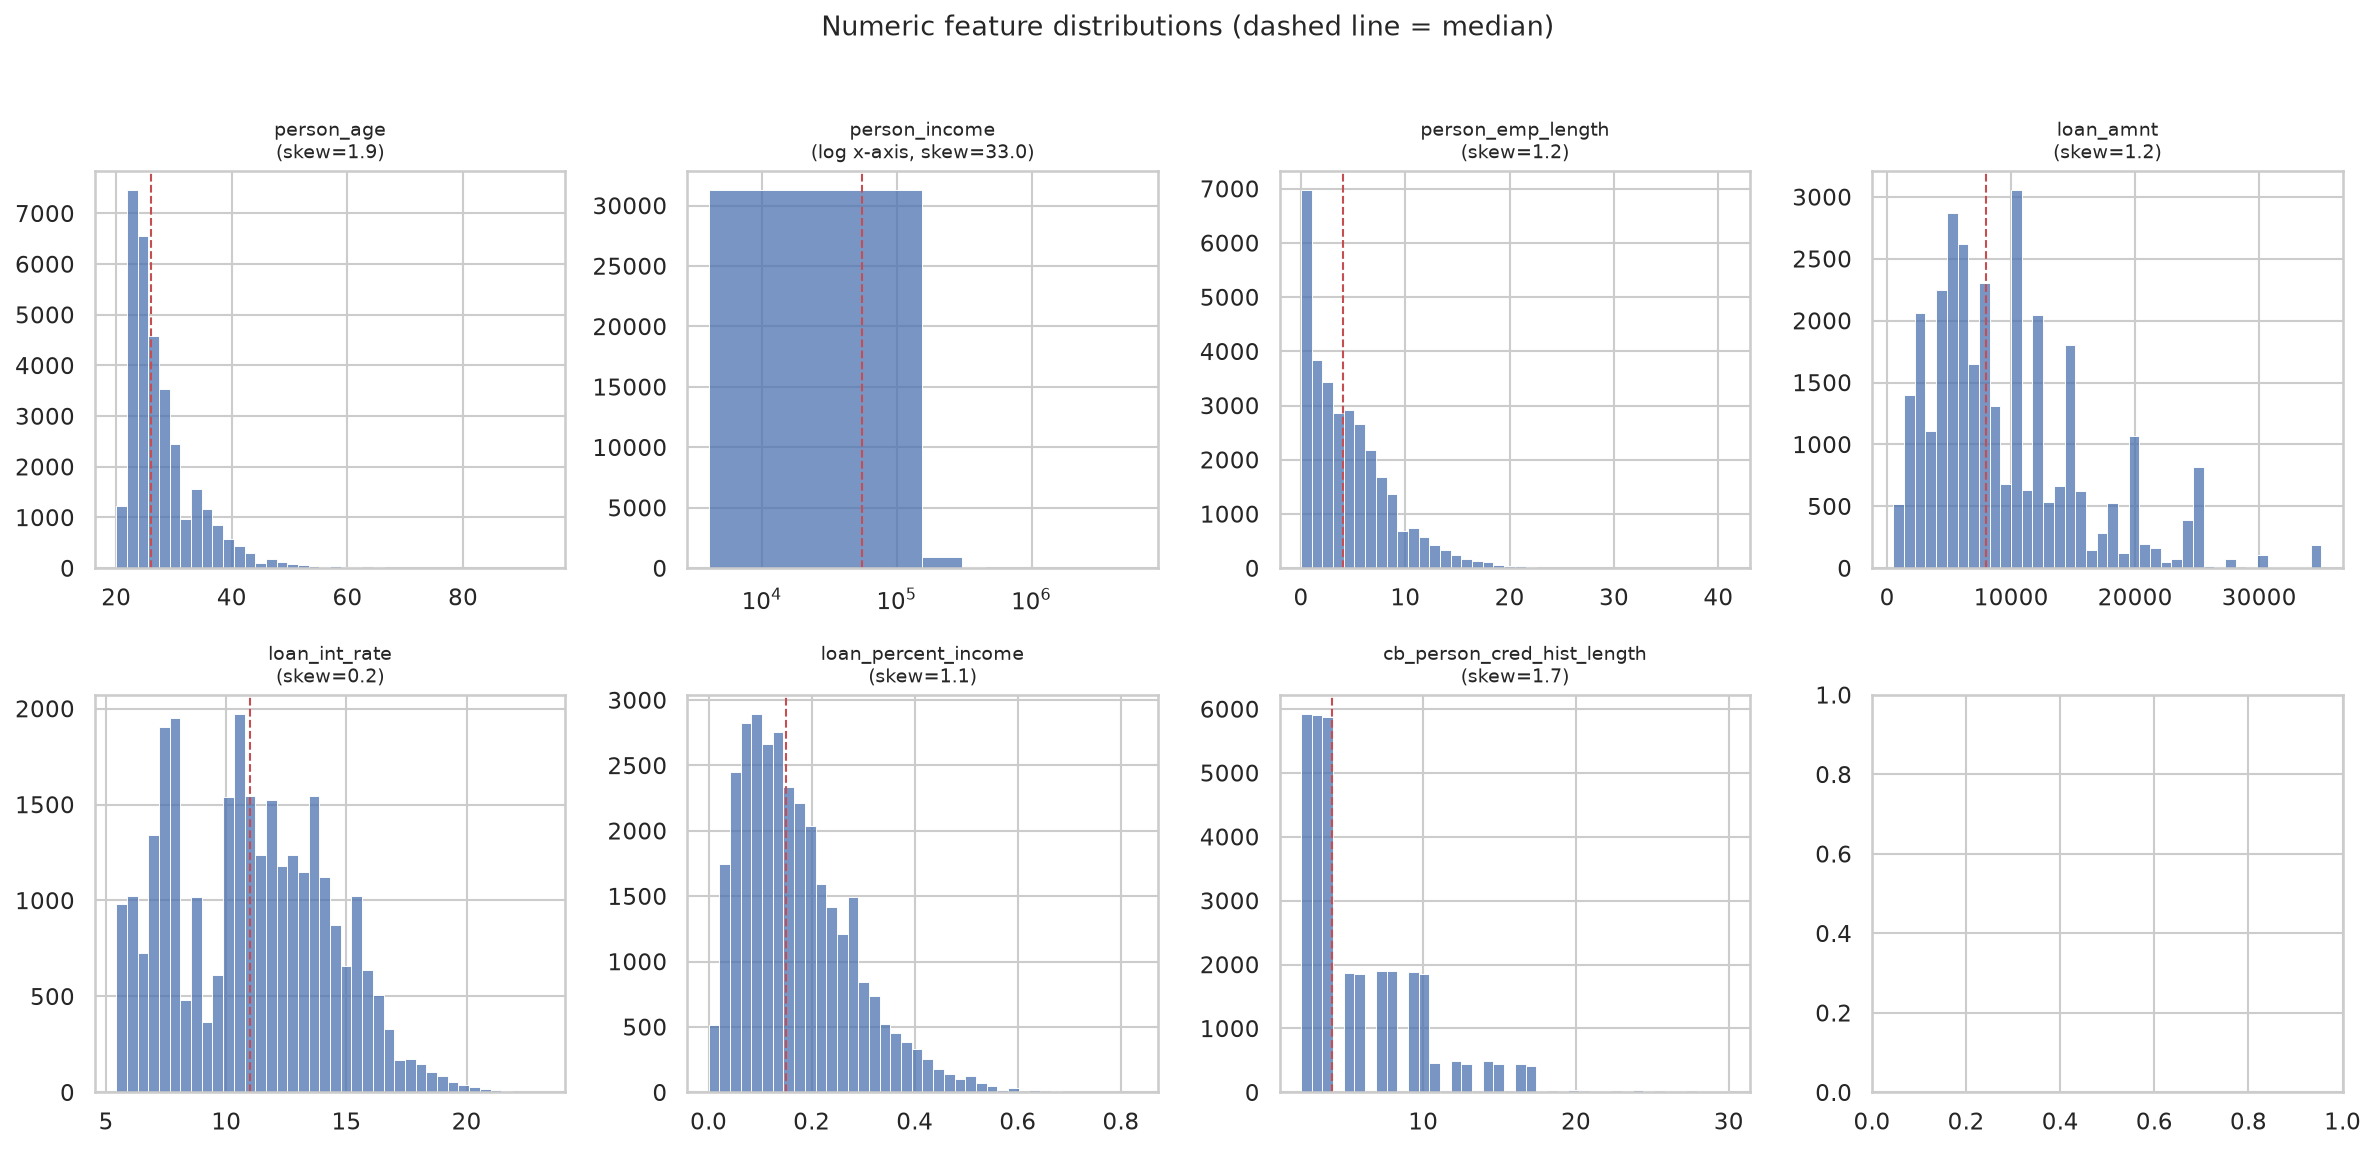

In [12]:
show_figure("03_numeric_distributions.png", width=1100)

In [13]:
pd.DataFrame(summary["numeric_summary"]).T[["mean", "median", "skew", "min", "max"]].round(2)

,mean,median,skew,min,max
person_age,27.73,26.00,1.94,20.00,94.00
person_income,66091.64,55000.00,32.96,4000.00,6000000.00
person_emp_length,4.78,4.00,1.25,0.00,41.00
loan_amnt,9593.85,8000.00,1.19,500.00,35000.00
loan_int_rate,11.02,10.99,0.21,5.42,23.22
loan_percent_income,0.17,0.15,1.06,0.00,0.83
cb_person_cred_hist_length,5.81,4.00,1.66,2.00,30.00


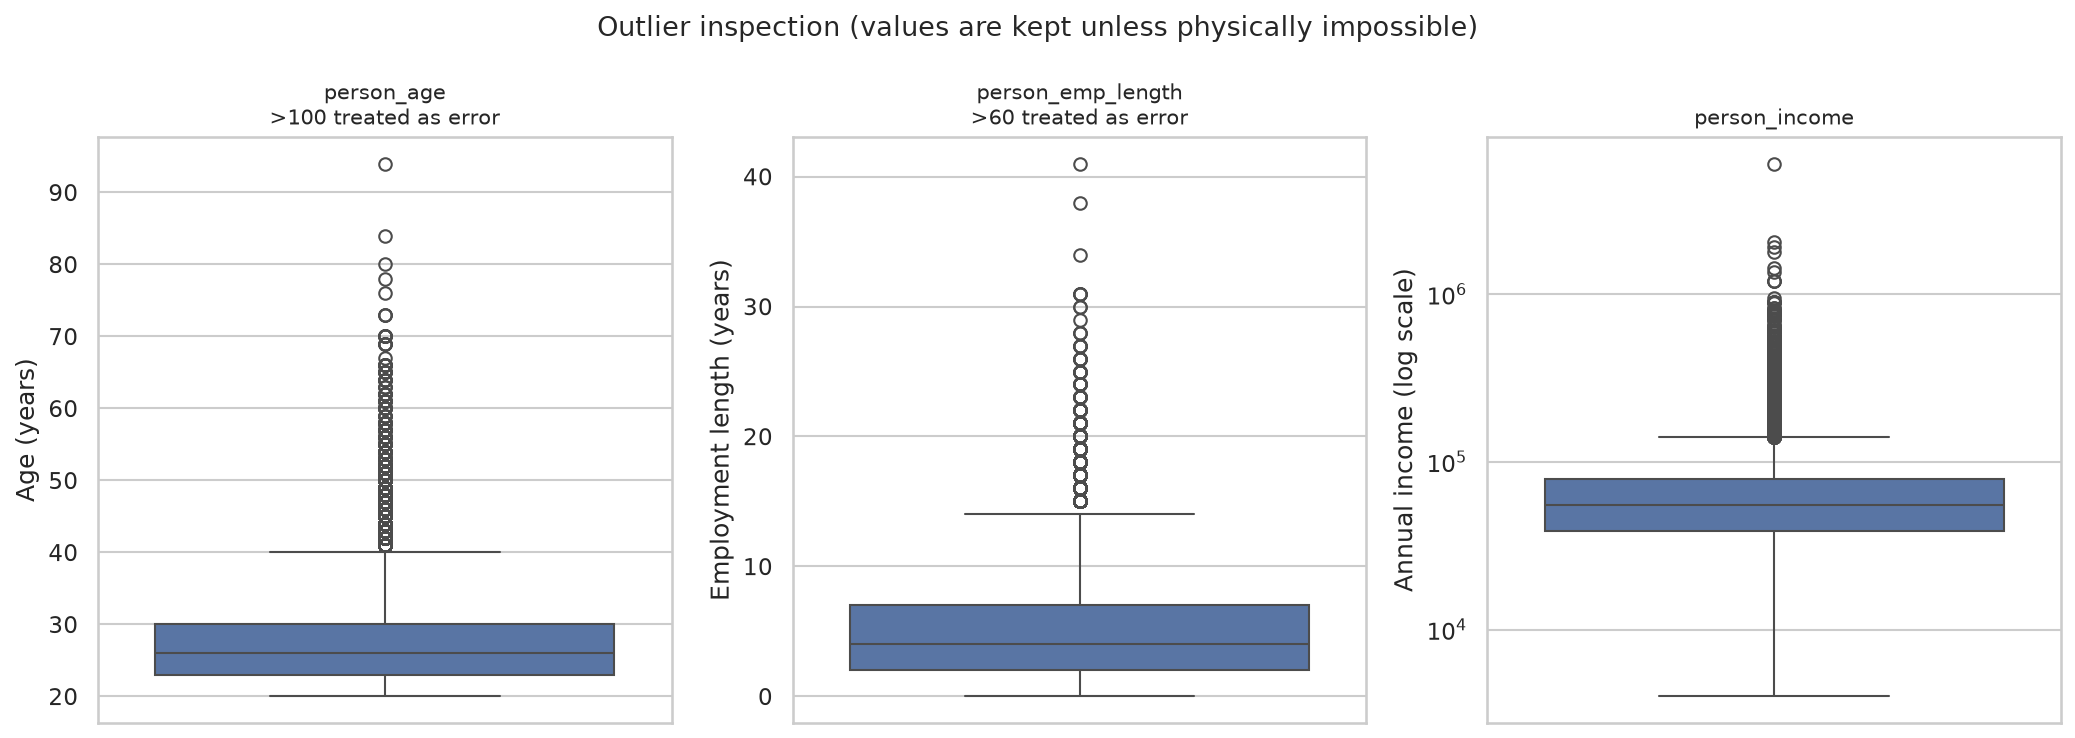

In [14]:
show_figure("08_outliers.png", width=1050)

## 6. Correlation with default

Spearman correlation is rank-based, so it is not dominated by the income outliers.
A positive value means "higher feature → higher default rate"; this is association,
**not causation**.

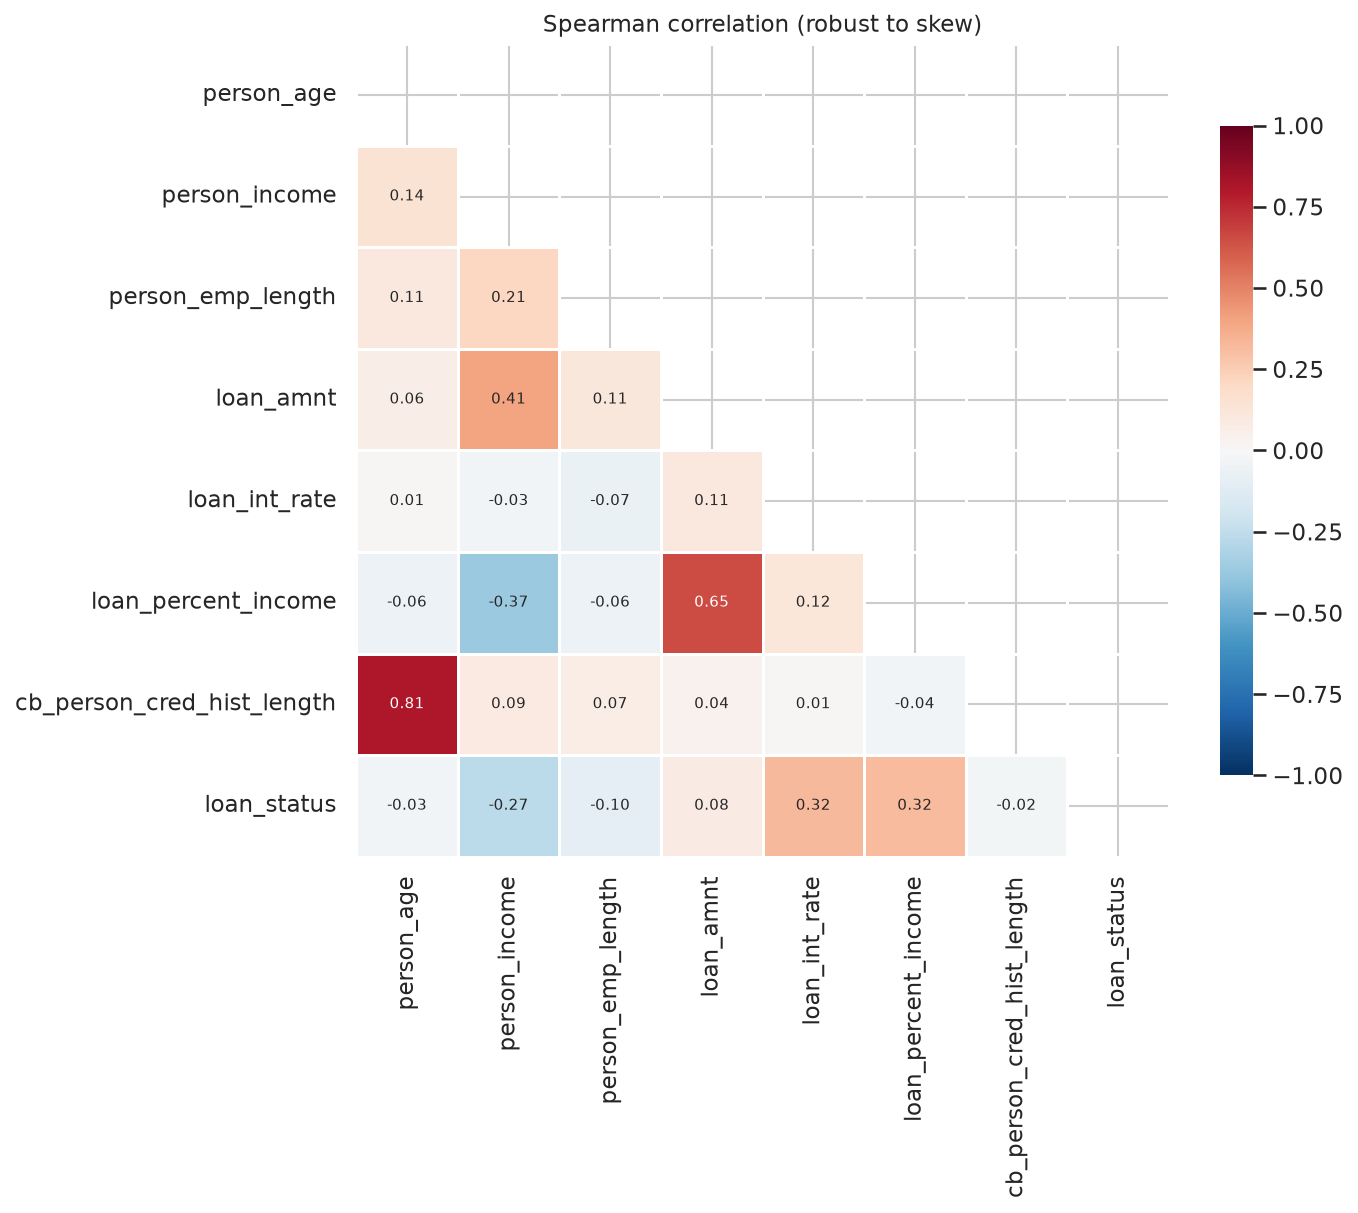

In [15]:
show_figure("04_correlation_heatmap.png", width=800)

In [16]:
pd.Series(summary["spearman_correlation_with_target"], name="spearman_rho").to_frame().round(3)

,spearman_rho
loan_int_rate,0.321
loan_percent_income,0.317
person_income,-0.272
person_emp_length,-0.098
loan_amnt,0.084
person_age,-0.035
cb_person_cred_hist_length,-0.025


The strongest numerical signals are the interest rate (+0.32), the loan-to-income
ratio (+0.32) and income (−0.27). Interest rate and grade are set by the lender and
already contain risk information; that is useful for prediction but means the model
is partly learning the lender's own assessment. We will discuss this limitation in
Stage 4.

## 7. Default rate by category

`loan_grade` is ordinal: A is the safest grade and G the riskiest. If the default
rate rises monotonically, ordinal encoding preserves that order better than
one-hot encoding.

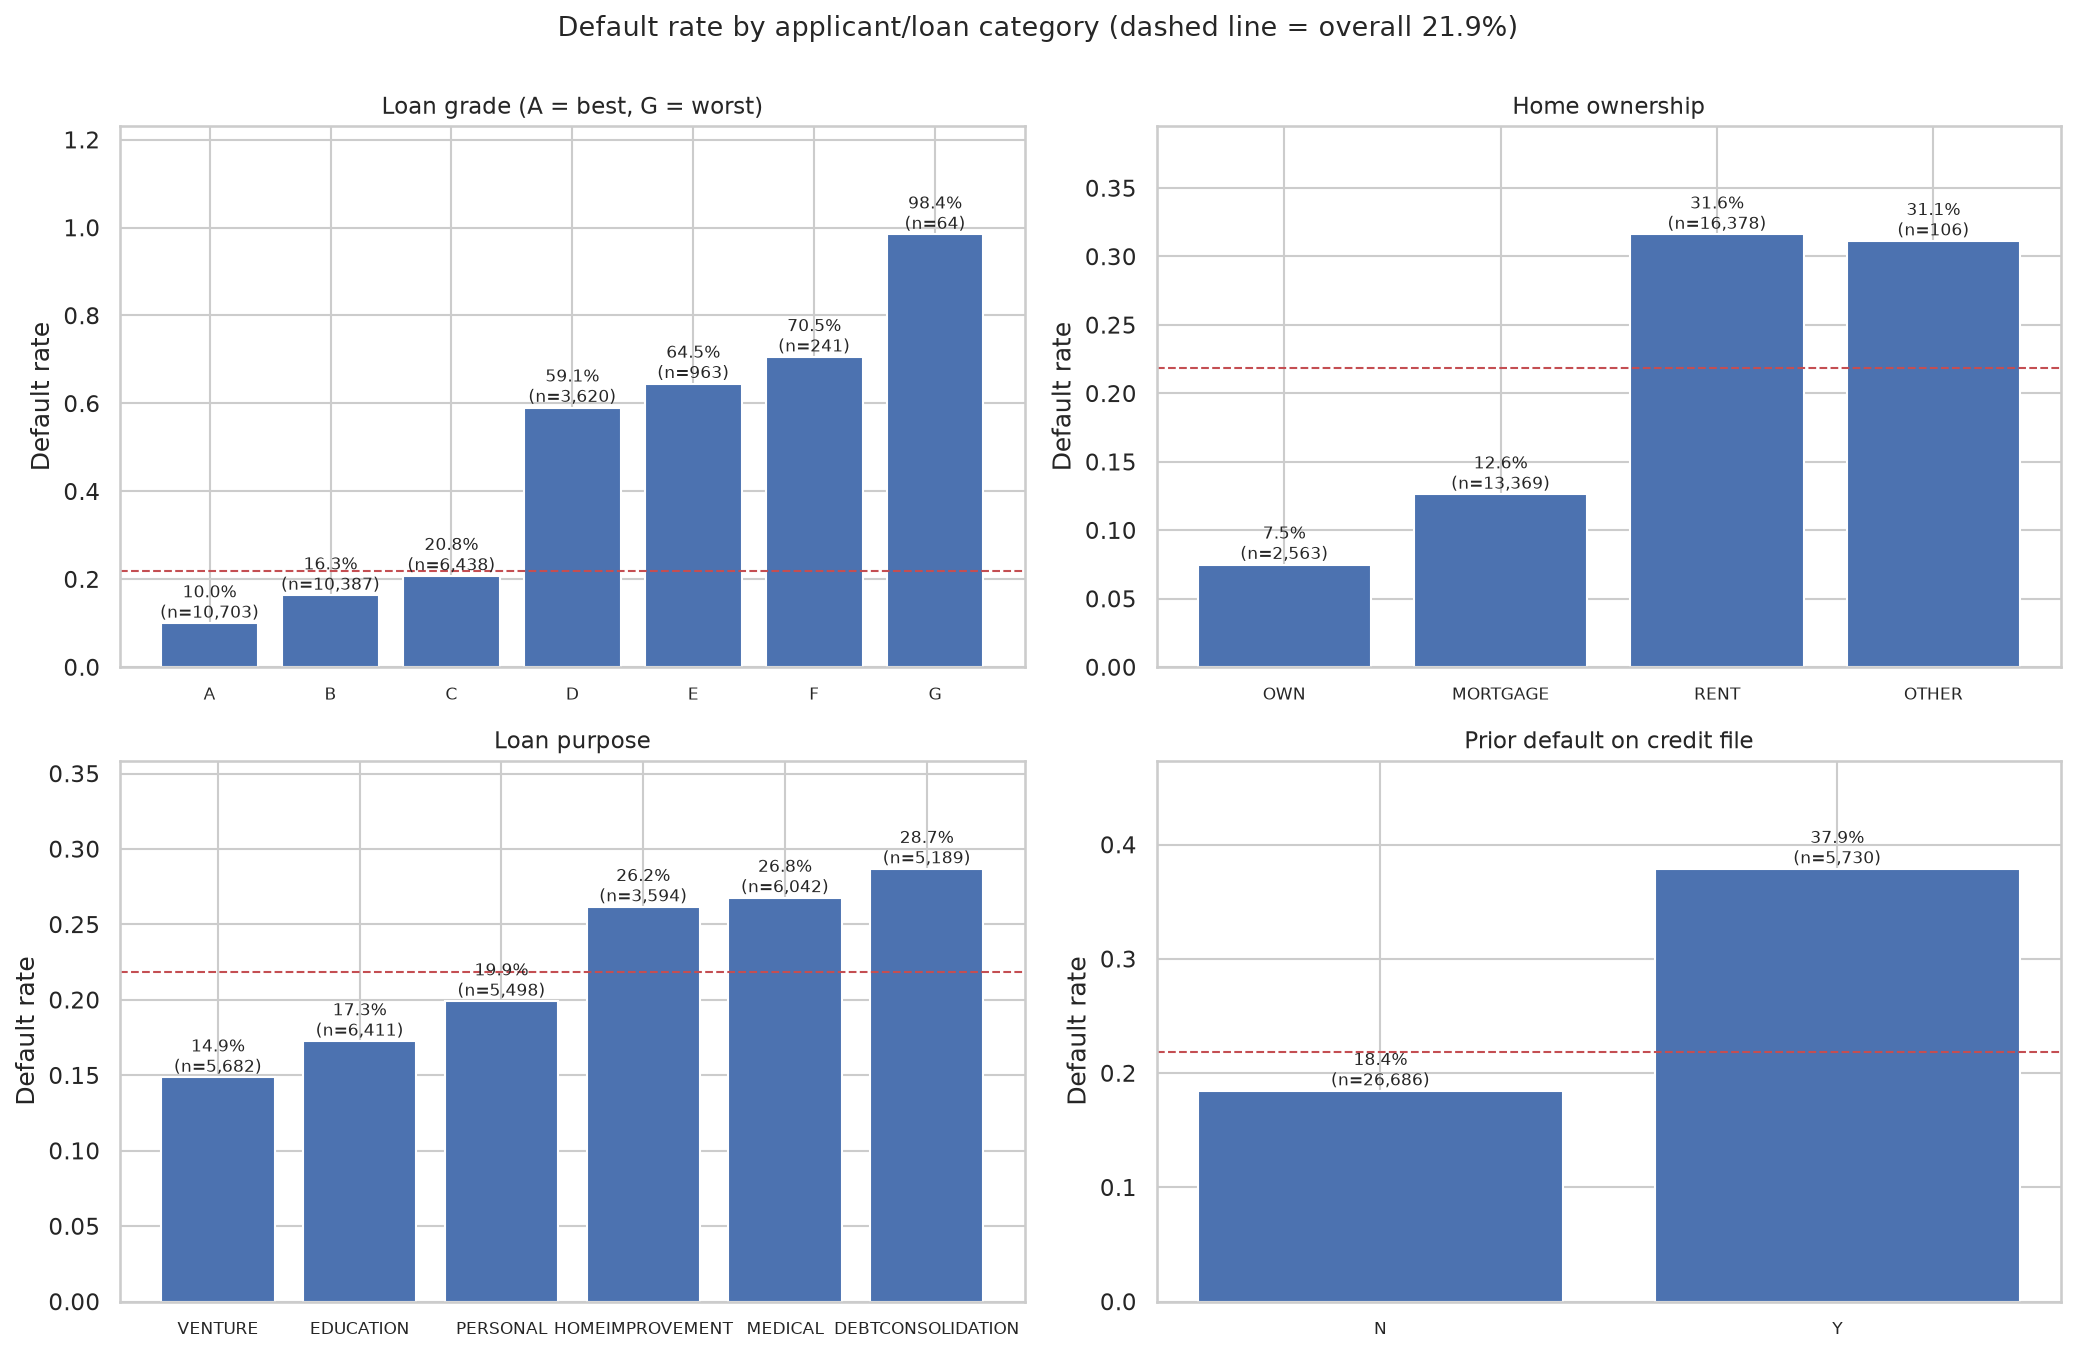

In [17]:
show_figure("05_default_rate_by_category.png", width=1100)

In [18]:
grade = pd.DataFrame(summary["categorical_default_rates"]["loan_grade"]).T
grade["default_rate"] = grade["default_rate"].round(3)
grade

,default_rate,count
A,0.100,10703.0
B,0.163,10387.0
C,0.208,6438.0
D,0.591,3620.0
E,0.645,963.0
F,0.705,241.0
G,0.984,64.0


**Business reading.** Grade A defaults at ~10%, while grade G is close to 98%.
Renting is associated with a ~32% default rate versus ~7.5% for owners. Borrowers
with a prior default on file default at ~38% versus ~18%. These are strong
associations, but they may overlap with each other — a multivariate model is needed
to separate them.

## 8. Numerical features by outcome

Boxplots show the distribution, not just the average. The default group has a
higher interest rate and a higher loan-to-income ratio; income overlaps heavily,
which is why a single feature is not enough.

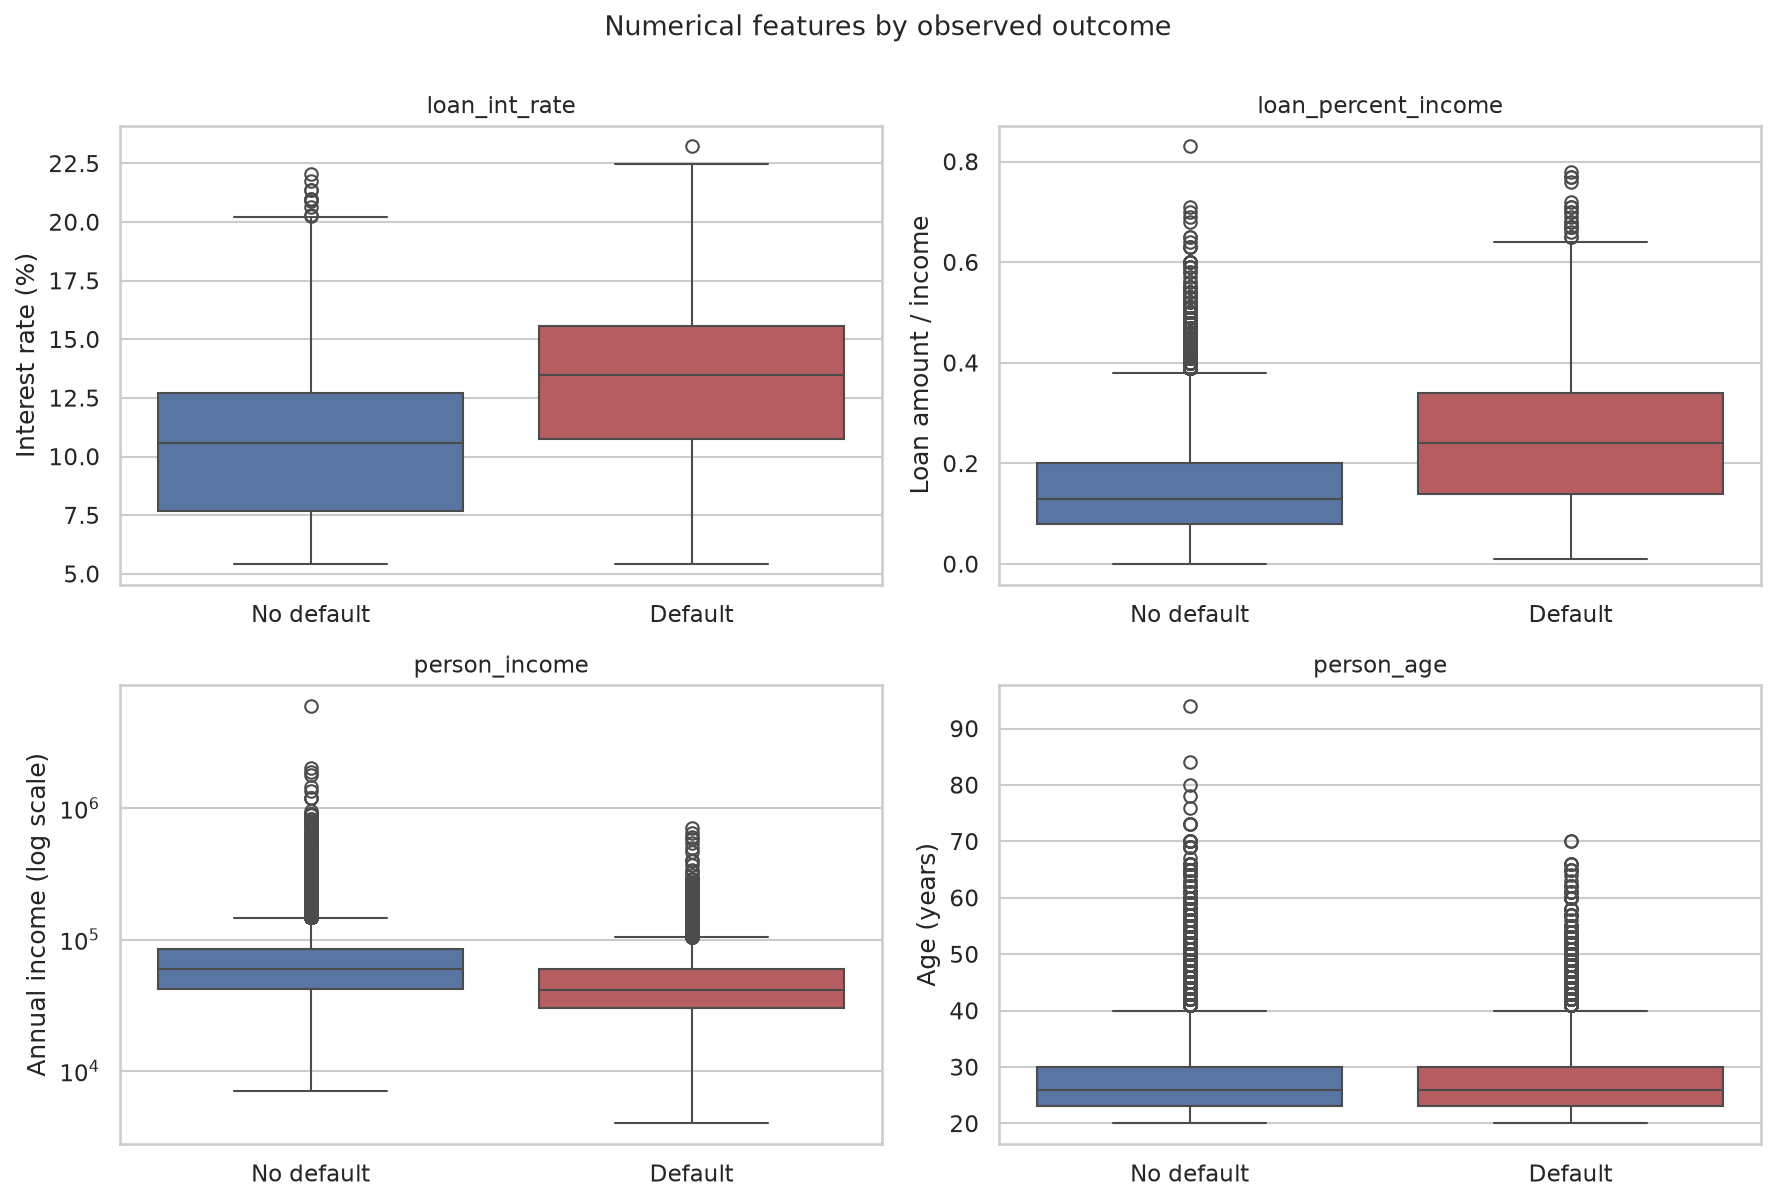

In [19]:
show_figure("06_numeric_by_target.png", width=950)

## 9. Redundancy check: `loan_percent_income`

The dataset already contains `loan_percent_income`. Is it just
`loan_amnt / person_income`, and should we add that ratio as a new feature?

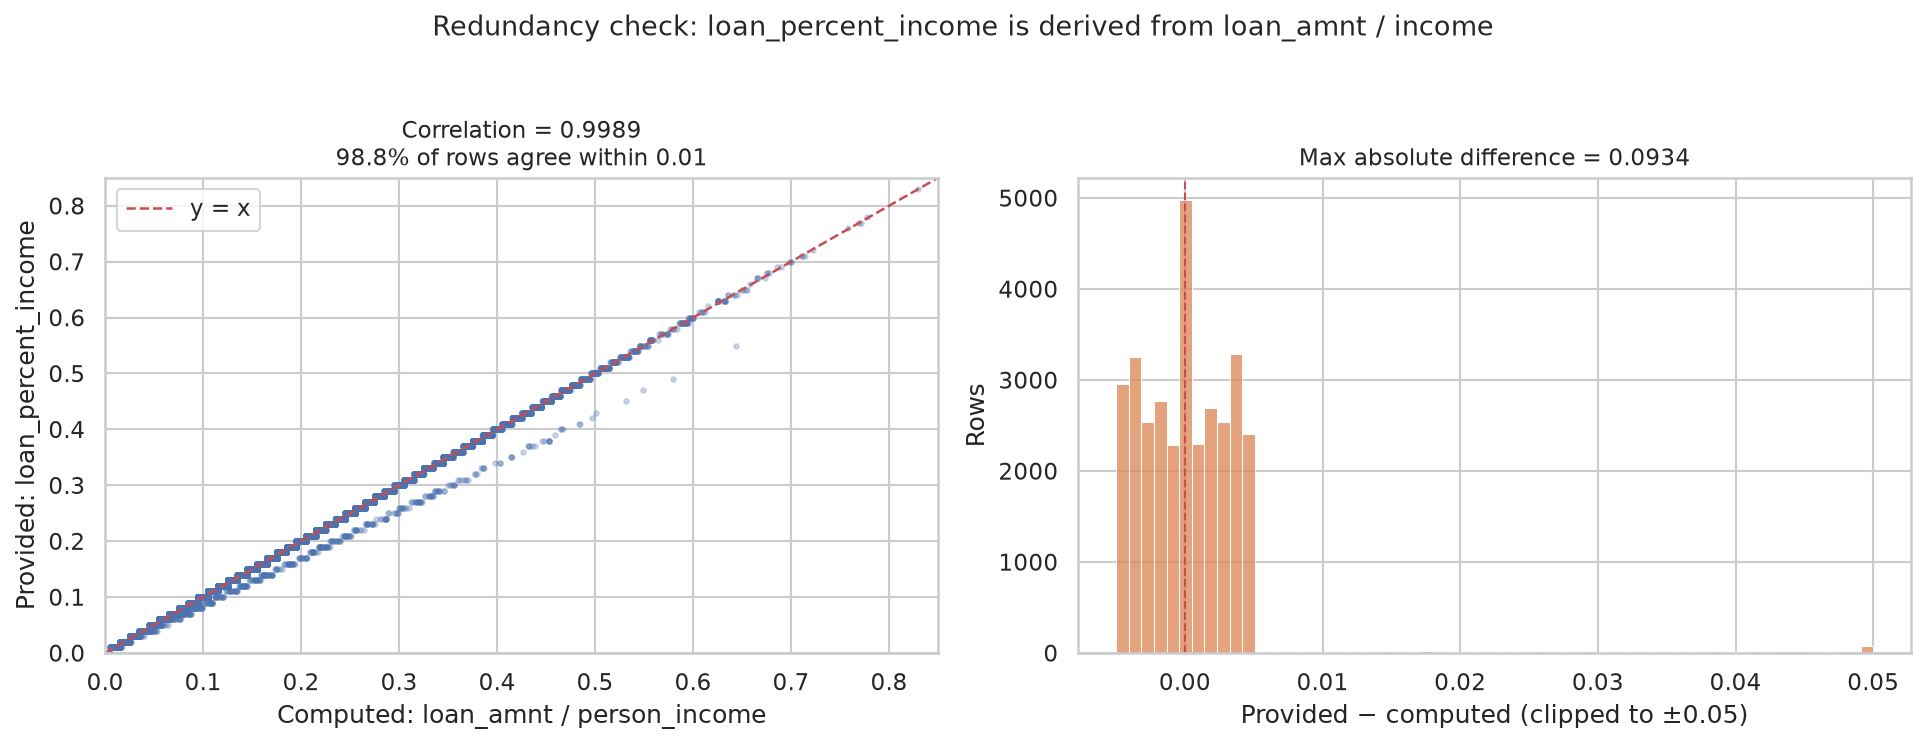

In [20]:
show_figure("07_percent_income_redundancy.png", width=1050)

In [21]:
calc = clean["loan_amnt"] / clean["person_income"]
difference = (calc - clean["loan_percent_income"]).abs()
print(f"Pearson correlation: {calc.corr(clean['loan_percent_income']):.4f}")
print(f"Rows within 0.01: {(difference <= 0.01).mean():.1%}")
print(f"Maximum difference: {difference.max():.4f}")
print("Rows differing by more than 0.01:", int((difference > 0.01).sum()))

Pearson correlation: 0.9989
Rows within 0.01: 98.8%
Maximum difference: 0.0934
Rows differing by more than 0.01: 387


The provided column is almost identical to the ratio, so adding a second copy would
only duplicate information. **Decision:** keep `loan_percent_income` and do not
engineer `loan_amnt / person_income` again.

I also tested two additional ratio features (`income_per_credit_year` and
`employment_length / (age − 17)`) during development: 5-fold CV ROC-AUC moved
from 0.8730 to 0.8737 (+0.0007, fold-to-fold std ≈ 0.004), which is noise rather
than a real gain, so they were left out. Rejecting a feature because it does not
earn its complexity is part of good feature engineering.

## 10. Train/test split — no leakage

Rules used here:

- **80/20 stratified split**, `random_state=42`: the default rate is kept in both
  parts, and the split is reproducible.
- The test set is **not** used to choose features or tune anything in this stage.
- Cleaning is row-wise and stateless, so it can happen before the split.
- Imputation, scaling and encoding happen **inside** the pipeline and are fitted
  on `X_train` only.

In [22]:
X_train, X_test, y_train, y_test = split_data(clean)
print(f"Train: {len(X_train):,} rows | default rate {y_train.mean():.2%}")
print(f"Test : {len(X_test):,} rows | default rate {y_test.mean():.2%}")
print("Target included in features?", TARGET in X_train.columns)
print("Input feature count:", len(FEATURE_COLUMNS))
print("Features:", FEATURE_COLUMNS)

Train: 25,932 rows | default rate 21.87%
Test : 6,484 rows | default rate 21.87%
Target included in features? False
Input feature count: 11
Features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade', 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file']


## 11. The preprocessing pipeline

Each branch has one job:

| Branch | Columns | Steps |
|---|---|---|
| `num_base` | age, employment length, interest rate, loan-to-income, credit history | median impute (+ missing indicator) → standardise |
| `num_log` | income, loan amount | median impute → `log1p` → standardise |
| `grade` | loan grade | most-frequent impute → ordinal encode A→0 … G→6 |
| `cat` | home ownership, loan intent, prior default | most-frequent impute → one-hot encode |

`remainder="drop"` guarantees that `loan_status` can never accidentally become a
feature, even if someone passes a DataFrame that still contains it.

In [23]:
preprocessor = build_preprocessor()
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded train shape:", X_train_encoded.shape)
print("Encoded test shape :", X_test_encoded.shape)
print("All values finite  :", np.isfinite(X_train_encoded).all())

names = preprocessor.get_feature_names_out()
print("Encoded columns:", len(names))
indicator_names = [name for name in names if "missingindicator" in name]
print(f"Missing-value indicators ({len(indicator_names)}):", indicator_names)
list(names[:10])

Encoded train shape: (25932, 23)
Encoded test shape : (6484, 23)
All values finite  : True
Encoded columns: 23
Missing-value indicators (3): ['num_base__missingindicator_person_age', 'num_base__missingindicator_person_emp_length', 'num_base__missingindicator_loan_int_rate']


['num_base__person_age',
 'num_base__person_emp_length',
 'num_base__loan_int_rate',
 'num_base__loan_percent_income',
 'num_base__cb_person_cred_hist_length',
 'num_base__missingindicator_person_age',
 'num_base__missingindicator_person_emp_length',
 'num_base__missingindicator_loan_int_rate',
 'num_log__person_income',
 'num_log__loan_amnt']

In [24]:
imputer = preprocessor.named_transformers_["num_base"].named_steps["imputer"]
idx = list(preprocessor.transformers_[0][2]).index("person_emp_length")
print("Median learned by imputer :", imputer.statistics_[idx])
print("Median of the training set:", X_train["person_emp_length"].median())
print("The test set was not used to compute this value.")

Median learned by imputer : 4.0
Median of the training set: 4.0
The test set was not used to compute this value.


### Leakage checklist

- [x] Target excluded from `X`
- [x] Split before fitting any transformer
- [x] Imputer/scaler/encoder fitted on `X_train` only
- [x] Unknown categories handled with `handle_unknown`
- [x] No target-based feature engineering
- [x] Duplicate rows removed before splitting
- [x] `loan_status` impossible to include via `remainder="drop"`

## 12. Final findings

The cell below builds the summary from the computed values, so it stays correct if
the data changes.

In [25]:
display(Markdown(f"""
### Key findings

- **{summary['dataset']['rows_raw']:,} raw rows → {summary['cleaning']['rows_after_cleaning']:,} after cleaning**
  ({summary['cleaning']['duplicate_rows']:,} exact duplicates removed).
- **{summary['dataset']['default_rate']:.1%} default rate**
  ({summary['dataset']['target_counts']['default_1']:,} defaults). The majority-class
  baseline is {(1 - summary['dataset']['default_rate']):.1%} accuracy but zero recall.
- **Missing values:** {summary['dataset']['missing_values']['loan_int_rate']:,} in
  `loan_int_rate`, {summary['dataset']['missing_values']['person_emp_length']:,} in
  `person_emp_length`; missing employment length is associated with more defaults.
- **Strongest associations:** interest rate (ρ =
  {summary['spearman_correlation_with_target']['loan_int_rate']:+.2f}), loan-to-income
  (ρ = {summary['spearman_correlation_with_target']['loan_percent_income']:+.2f}),
  income (ρ = {summary['spearman_correlation_with_target']['person_income']:+.2f}).
- **Grade is monotonic:** {summary['categorical_default_rates']['loan_grade']['A']['default_rate']:.1%}
  for A up to {summary['categorical_default_rates']['loan_grade']['G']['default_rate']:.1%}
  for G, so it is ordinal-encoded.
- **Redundancy:** `loan_percent_income` correlates
  {summary['redundancy']['pearson_correlation']:.4f} with `loan_amnt / person_income`;
  the duplicate feature was not added.
- **Split:** {summary['split']['train_rows']:,} train / {summary['split']['test_rows']:,}
  test rows, both at ~{summary['split']['test_default_rate']:.1%} default.

### Limitations to remember

1. This is a **synthetic/simulated** dataset, not real bank data.
2. Correlations are associations; they do not prove causation.
3. Interest rate and grade are lender-assigned and may already encode risk.
4. The model will support a human decision, never replace it.

**Next stage:** train Logistic Regression, Decision Tree and Random Forest on this
exact pipeline, compare them with stratified cross-validation, and evaluate the
chosen model once on the untouched test set.
"""))


### Key findings

- **32,581 raw rows → 32,416 after cleaning**
  (165 exact duplicates removed).
- **21.9% default rate**
  (7,089 defaults). The majority-class
  baseline is 78.1% accuracy but zero recall.
- **Missing values:** 3,116 in
  `loan_int_rate`, 895 in
  `person_emp_length`; missing employment length is associated with more defaults.
- **Strongest associations:** interest rate (ρ =
  +0.32), loan-to-income
  (ρ = +0.32),
  income (ρ = -0.27).
- **Grade is monotonic:** 10.0%
  for A up to 98.4%
  for G, so it is ordinal-encoded.
- **Redundancy:** `loan_percent_income` correlates
  0.9989 with `loan_amnt / person_income`;
  the duplicate feature was not added.
- **Split:** 25,932 train / 6,484
  test rows, both at ~21.9% default.

### Limitations to remember

1. This is a **synthetic/simulated** dataset, not real bank data.
2. Correlations are associations; they do not prove causation.
3. Interest rate and grade are lender-assigned and may already encode risk.
4. The model will support a human decision, never replace it.

**Next stage:** train Logistic Regression, Decision Tree and Random Forest on this
exact pipeline, compare them with stratified cross-validation, and evaluate the
chosen model once on the untouched test set.
